In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
!ls -lh /content/drive/MyDrive/archive.zip

-rw------- 1 root root 105M Oct 16 13:34 /content/drive/MyDrive/archive.zip


In [ ]:
!unzip -q "/content/drive/MyDrive/archive.zip" -d data

In [ ]:
!ls data
!ls data/train/REAL | wc -l
!ls data/train/FAKE | wc -l
!ls data/test/REAL | wc -l
!ls data/test/FAKE | wc -l

test  train
50000
50000
10000
10000


In [ ]:
import cv2, os, numpy as np

def load_images(folder, label, limit=5000):
    X, y = [], []
    for name in os.listdir(folder)[:limit]:
        img = cv2.imread(os.path.join(folder, name))
        img = cv2.resize(img, (32, 32))
        X.append(img / 255.0)   # normalize to 0-1
        y.append(label)
    return X, y

Xr, yr = load_images("data/train/REAL", 0)
Xf, yf = load_images("data/train/FAKE", 1)

X = np.array(Xr + Xf)
y = np.array(yr + yf)
print(X.shape, y.shape)

(10000, 32, 32, 3) (10000,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_val.shape)

(8000, 32, 32, 3) (2000, 32, 32, 3)


In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

model = keras.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid"),
])

model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       147,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 166,977 (652.25 KB)

 Trainable params: 166,977 (652.25 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=64,
)

Epoch 1/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 8s 19ms/step - accuracy: 0.6876 - loss: 0.5794 - val_accuracy: 0.7885 - val_loss: 0.4659
Epoch 2/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7750 - loss: 0.4665 - val_accuracy: 0.7795 - val_loss: 0.4652
Epoch 3/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8184 - loss: 0.4041 - val_accuracy: 0.8355 - val_loss: 0.3683
Epoch 4/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8432 - loss: 0.3637 - val_accuracy: 0.8515 - val_loss: 0.3323
Epoch 5/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8601 - loss: 0.3306 - val_accuracy: 0.8635 - val_loss: 0.3048
Epoch 6/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8674 - loss: 0.3092 - val_accuracy: 0.8655 - val_loss: 0.3146
Epoch 7/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8789 - loss: 0.2946 - val_accuracy: 0.8605 - val_loss: 0.3271
Epoch 8/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8829 - loss: 0.2914 - val_accuracy: 0

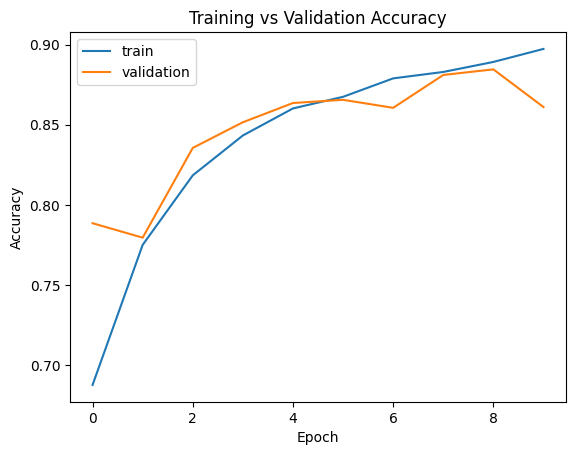

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="validation")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend()
plt.title("Training vs Validation Accuracy")
plt.show()

In [ ]:
Xtr, ytr = load_images("data/test/REAL", 0, limit=1000)
Xtf, ytf = load_images("data/test/FAKE", 1, limit=1000)
X_test = np.array(Xtr + Xtf)
y_test = np.array(ytr + ytf)

loss, acc = model.evaluate(X_test, y_test)
print(f"Test accuracy: {acc:.4f}")

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8505 - loss: 0.3470
Test accuracy: 0.8505


63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
              precision    recall  f1-score   support

        REAL       0.93      0.76      0.84      1000
        FAKE       0.80      0.94      0.86      1000

    accuracy                           0.85      2000
   macro avg       0.86      0.85      0.85      2000
weighted avg       0.86      0.85      0.85      2000



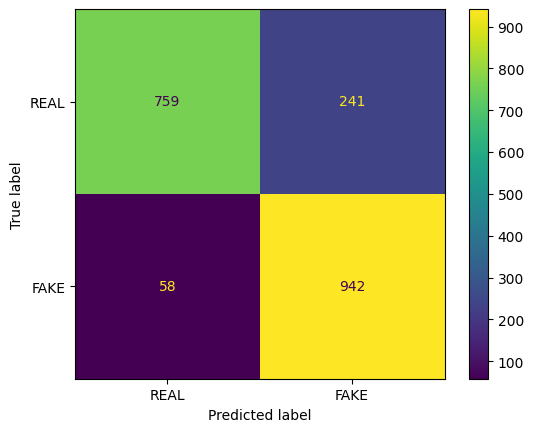

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

y_pred = (model.predict(X_test) > 0.5).astype(int).ravel()
print(classification_report(y_test, y_pred, target_names=["REAL", "FAKE"]))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["REAL", "FAKE"]).plot()
plt.show()

In [ ]:
Xr, yr = load_images("data/train/REAL", 0, limit=20000)
Xf, yf = load_images("data/train/FAKE", 1, limit=20000)
X = np.array(Xr + Xf)
y = np.array(yr + yf)

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_val.shape)

(32000, 32, 32, 3) (8000, 32, 32, 3)


In [ ]:
model2 = keras.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.RandomFlip("horizontal"),
    layers.RandomTranslation(0.1, 0.1),
    layers.Conv2D(32, 3, activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(1, activation="sigmoid"),
])

model2.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

history2 = model2.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=64,
)

Epoch 1/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.7908 - loss: 0.4558 - val_accuracy: 0.8520 - val_loss: 0.3384
Epoch 2/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.8463 - loss: 0.3502 - val_accuracy: 0.8056 - val_loss: 0.4508
Epoch 3/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.8637 - loss: 0.3177 - val_accuracy: 0.7738 - val_loss: 0.5334
Epoch 4/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.8766 - loss: 0.2957 - val_accuracy: 0.7736 - val_loss: 0.5922
Epoch 5/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.8818 - loss: 0.2842 - val_accuracy: 0.8966 - val_loss: 0.2435
Epoch 6/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.8861 - loss: 0.2706 - val_accuracy: 0.8904 - val_loss: 0.2534
Epoch 7/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.8914 - loss: 0.2643 - val_accuracy: 0.7994 - val_loss: 0.4442
Epoch 8/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.8981 - loss: 0.2530 - val_accu

In [ ]:
loss, acc = model2.evaluate(X_test, y_test)
print(f"Test accuracy: {acc:.4f}")

y_pred = (model2.predict(X_test) > 0.5).astype(int).ravel()
print(classification_report(y_test, y_pred, target_names=["REAL", "FAKE"]))

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8415 - loss: 0.3912
Test accuracy: 0.8415
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
              precision    recall  f1-score   support

        REAL       0.98      0.69      0.81      1000
        FAKE       0.76      0.99      0.86      1000

    accuracy                           0.84      2000
   macro avg       0.87      0.84      0.84      2000
weighted avg       0.87      0.84      0.84      2000

